# UGC Games: Roblox & Fortnite — exploratory analysis

A first look at the **UGC Games: Roblox & Fortnite Tracker** dataset: hourly and daily snapshots of
Roblox experiences and Fortnite islands, collected automatically with GitHub Actions
([source code and methodology](https://github.com/Agustin-Molina/ugc-game-analytics)).

The project asks three questions:

1. What makes a game **explode** (grow fast) or **sustain** (keep its players)?
2. Which **niches** have growing demand and few competitors?
3. Can the **first 3–7 days** of metrics tell which new games will take off?

This notebook does not answer them yet; it maps the data. It shows what is tracked, how
concentrated attention is, when people play, which genres win on each platform, and which signals
(creator track record, title clones, retention) look worth modelling. The dataset is updated weekly,
so every number below is recomputed on each run.

## Setup

In [1]:
import glob
import os
import re
from collections import defaultdict
from pathlib import Path

try:
    import duckdb
except ImportError:  # the Kaggle image usually ships it
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckdb"])
    import duckdb

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 140)


def find_data_dir() -> Path:
    """Kaggle input folder, or the local export (python -m pipeline.export --out export)."""
    candidates = [os.environ.get("UGC_EXPORT_DIR"), "/kaggle/input/ugc-games-roblox-fortnite",
                  *glob.glob("/kaggle/input/*ugc-games-roblox-fortnite*"), "../export", "export"]
    for c in candidates:
        if c and Path(c, "roblox_games.parquet").exists():
            return Path(c)
    raise FileNotFoundError("dataset not found: set UGC_EXPORT_DIR")


DATA = find_data_dir()
con = duckdb.connect()
# One view per table; monthly files (roblox_snapshots_2026-11.parquet, ...) are unioned.
tables = defaultdict(list)
for f in sorted(DATA.glob("*.parquet")):
    tables[re.sub(r"_\d{4}-\d{2}$", "", f.stem)].append(f.as_posix())
for name, files in tables.items():
    con.execute(f"create or replace view {name} as select * from read_parquet({files})")


def q(sql: str) -> pd.DataFrame:
    return con.sql(sql).df()


# Chart style: one color per platform, recessive grid.
ROBLOX, FORTNITE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8c8b85",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})
fmt_k = mticker.FuncFormatter(lambda v, _: f"{v / 1e6:.0f}M" if v >= 1e6
                              else f"{v / 1e3:.0f}k" if v >= 1e3 else f"{v:.0f}")
print("data:", DATA)
pd.DataFrame([(n, len(f), sum(Path(x).stat().st_size for x in f) / 1e6)
              for n, f in tables.items()], columns=["table", "files", "MB"]).round(1)

data: ../export


,table,files,MB
0,fortnite_daily,1,1.5
1,fortnite_events,1,0.0
2,fortnite_island_metrics,1,0.7
3,fortnite_islands,1,16.5
4,fortnite_islands_history,1,10.2
5,fortnite_niche_opportunity,1,0.0
6,fortnite_snapshots,1,4.2
7,fortnite_tier_history,1,0.9
8,roblox_chart_positions,1,0.6
9,roblox_creator_games,1,0.9


## 1. What is tracked

Roblox has no public history, so the time series is built by polling: the Roblox explore charts
every hour, a daily keyword search to catch new launches, and every known experience at a frequency
set by its **tier** (hot hourly, warm daily, cold weekly). Fortnite publishes 7 days of metrics per
island, and the collector visits the whole public catalog at least weekly, so there are no gaps.

In [2]:
q("""
select 'Roblox' as platform, min(snapshot_at) as first, max(snapshot_at) as last,
       count(distinct universe_id) as games, count(*) as snapshot_rows
from roblox_snapshots
union all
select 'Fortnite', min(bucket_start), max(bucket_start), count(distinct island_code), count(*)
from fortnite_snapshots
""")

,platform,first,last,games,snapshot_rows
0,Roblox,2026-11-10 05:23:49.365675+00:00,2026-11-12 17:19:49.971515+00:00,6461,90472
1,Fortnite,2026-11-03 00:00:00.000000+00:00,2026-11-12 07:00:00.000000+00:00,29044,349170


In [3]:
tiers = q("""
select 'Roblox' as platform, tier, count(*) as games from roblox_games group by all
union all
select 'Fortnite', tier, count(*) from fortnite_islands group by all
""").pivot(index="platform", columns="tier", values="games")[["hot", "warm", "cold"]]
tiers

tier,hot,warm,cold
platform,,,
Fortnite,2786,141171,143619
Roblox,1851,3102,1508


Fortnite's catalog is huge (~290k listed islands), but most islands have no measurable players on a
given day: the API reports nothing for buckets under 5 unique players. Roblox is tracked from the
other side: only experiences that appeared in a chart or a search are known.

## 2. Attention is extremely concentrated

Concurrent players (CCU) of each game at its latest snapshot, ranked from the biggest down. Both
axes are logarithmic: a straight-ish line is the signature of a power law.

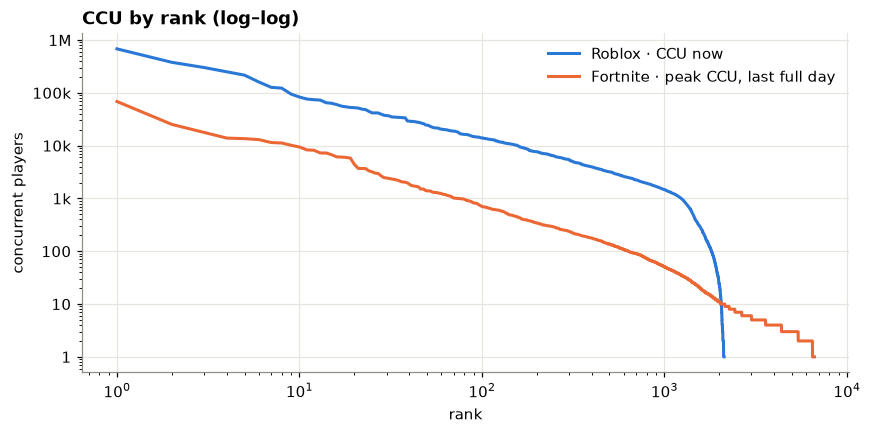

,Roblox (now),Fortnite (last day peak)
games with players,2123.000,6642.000
total CCU,9080447.000,579549.000
top 10 share,0.266,0.336
top 100 share,0.548,0.656
median CCU,1342.000,5.000


In [4]:
roblox_now = q("""
select universe_id, arg_max(playing, snapshot_at) as ccu from roblox_snapshots
where snapshot_at >= (select max(snapshot_at) from roblox_snapshots) - interval 2 hour
group by 1 having ccu > 0 order by ccu desc
""")
fortnite_day = q("""
select island_code, peak_ccu as ccu from fortnite_daily
where day = (select max(day) from fortnite_daily) and peak_ccu > 0 order by ccu desc
""")

fig, ax = plt.subplots()
for df, color, label in [(roblox_now, ROBLOX, "Roblox · CCU now"),
                         (fortnite_day, FORTNITE, "Fortnite · peak CCU, last full day")]:
    rank = range(1, len(df) + 1)
    ax.plot(rank, df["ccu"], color=color, label=label)
ax.set(xscale="log", yscale="log", xlabel="rank", ylabel="concurrent players",
       title="CCU by rank (log–log)")
ax.yaxis.set_major_formatter(fmt_k)
ax.legend()
plt.show()


def concentration(df):
    s = df["ccu"].sort_values(ascending=False)
    return {"games with players": len(s), "total CCU": int(s.sum()),
            "top 10 share": s.head(10).sum() / s.sum(),
            "top 100 share": s.head(100).sum() / s.sum(),
            "median CCU": s.median()}


pd.DataFrame({"Roblox (now)": concentration(roblox_now),
              "Fortnite (last day peak)": concentration(fortnite_day)}).round(3)

A handful of games take a large share of all players on both platforms. The Roblox list is
already filtered (it only contains games that were seen in charts or searches), so its real tail is
much longer than shown. Fortnite's catalog is complete, so its curve shows the whole tail.

## 3. When people play

Total CCU by hour of day (UTC), indexed to each platform's daily mean (100 = average hour). Roblox
uses the hourly snapshots of hot games (max per game and hour); Fortnite uses the hourly peak CCU of
active islands.

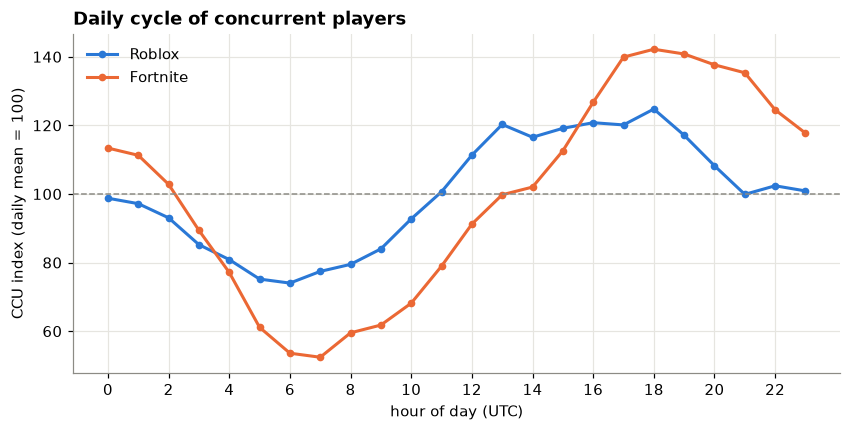

In [5]:
cycle = q("""
with r as (
    select date_trunc('hour', snapshot_at) as t, universe_id, max(playing) as ccu
    from roblox_snapshots
    where universe_id in (select universe_id from roblox_games where tier = 'hot')
    group by all
), rh as (select t, sum(ccu) as ccu from r group by 1),
fh as (
    select bucket_start as t, sum(peak_ccu) as ccu from fortnite_snapshots
    where interval = 'hour' group by 1
)
select 'Roblox' as platform, hour(t) as hour, avg(ccu) as ccu from rh group by all
union all
select 'Fortnite', hour(t), avg(ccu) from fh group by all
order by platform, hour
""")
cycle["index"] = cycle["ccu"] / cycle.groupby("platform")["ccu"].transform("mean") * 100

fig, ax = plt.subplots()
for platform, color in [("Roblox", ROBLOX), ("Fortnite", FORTNITE)]:
    d = cycle[cycle["platform"] == platform]
    ax.plot(d["hour"], d["index"], color=color, label=platform, marker="o", markersize=4)
ax.axhline(100, color="#8c8b85", linewidth=1, linestyle="--")
ax.set(xlabel="hour of day (UTC)", ylabel="CCU index (daily mean = 100)", xticks=range(0, 24, 2),
       title="Daily cycle of concurrent players")
ax.legend()
plt.show()

Both platforms bottom out in the early UTC morning (night in the Americas). Fortnite swings much
harder and peaks around the US afternoon, while Roblox's curve is flatter, with a long plateau from
midday to evening UTC: its audience is spread over more time zones. Timing matters for anything measured at a single moment: a
CCU snapshot taken at 06:00 UTC can show far fewer players than the same game at 18:00. That is why
the derived tables work with **daily peak CCU**.

## 4. Genres: what wins on each platform

Both platforms are mapped to one unified taxonomy of 25 genres (`genre_unified`; rules in
`config/genres.yaml` of the source repo). Bars show each genre's share of the platform's total daily
peak CCU (average over the observed days). Epic's own Fortnite islands are excluded: they are not
UGC competition.

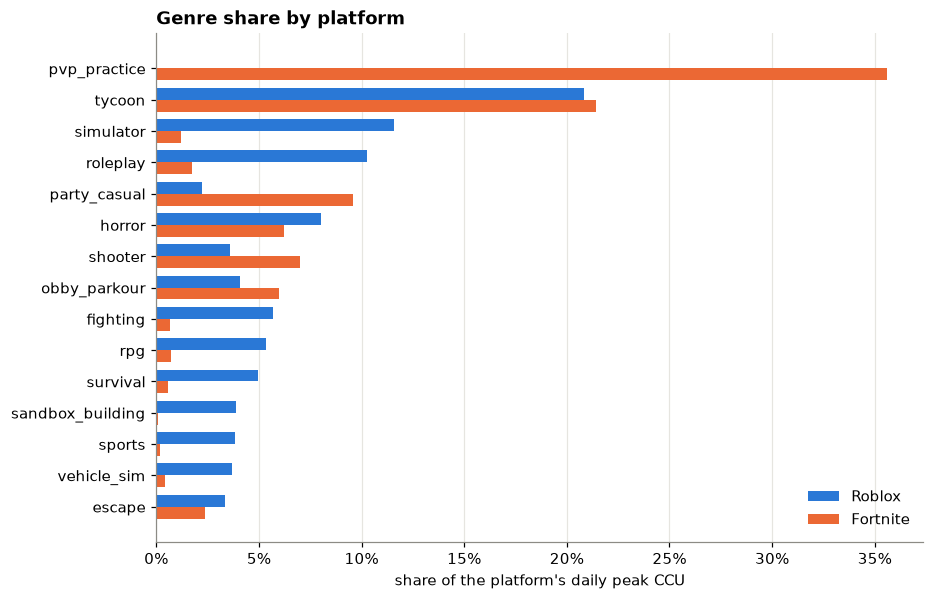

,genre,roblox,fortnite
0,pvp_practice,0.000,0.356
1,tycoon,0.208,0.214
2,simulator,0.116,0.012
3,roleplay,0.103,0.018
4,party_casual,0.022,0.096
5,horror,0.080,0.062
6,shooter,0.036,0.070
7,obby_parkour,0.041,0.060
8,fighting,0.057,0.007
9,rpg,0.053,0.007


In [6]:
genres = q("""
with r as (
    select genre_unified, sum(peak_ccu) / count(distinct day) as ccu
    from roblox_daily join roblox_games using (universe_id)
    where not is_partial group by 1
), f as (
    select genre_unified, sum(peak_ccu) / count(distinct day) as ccu
    from fortnite_daily join fortnite_islands using (island_code)
    where lower(creator_code) <> 'epic' group by 1
)
select coalesce(r.genre_unified, f.genre_unified) as genre,
       coalesce(r.ccu / sum(r.ccu) over (), 0) as roblox,
       coalesce(f.ccu / sum(f.ccu) over (), 0) as fortnite
from r full join f using (genre_unified)
where genre is not null and genre <> 'other'
order by greatest(roblox, fortnite) desc
limit 15
""")

fig, ax = plt.subplots(figsize=(9, 6))
y = range(len(genres))[::-1]
h = 0.38
ax.barh([v + h / 2 for v in y], genres["roblox"], height=h, color=ROBLOX, label="Roblox")
ax.barh([v - h / 2 for v in y], genres["fortnite"], height=h, color=FORTNITE, label="Fortnite")
ax.set_yticks(list(y), genres["genre"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.set(xlabel="share of the platform's daily peak CCU", title="Genre share by platform")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()
genres.round(3)

The two platforms reward different things. Fortnite is dominated by **PvP practice** maps (box
fights, 1v1 build fights, zone wars) built on the base game's combat. Roblox spreads its players over
tycoons, simulators, roleplay and horror. Tycoons and horror do well on both. Genres that are big on
one platform and small on the other (simulator, roleplay, fighting and RPG on Roblox; party games
and shooters on Fortnite) are the first candidates for "port the format" ideas.

## 5. Opportunity by niche (Fortnite, preliminary)

`fortnite_niche_opportunity` compares weekly demand (unique players) with the number of islands
competing for it. The headline `opportunity_score` needs two full weeks of coverage, so it is empty
in the first versions. Until then, `median_island_demand` (how many players a typical active island
gets) and `top10_share` (how much of the niche the 10 biggest islands take) already separate open
niches from saturated ones.

In [7]:
q("""
select genre_unified, islands_active, demand_w1,
       round(demand_per_active_island) as demand_per_island, median_island_demand,
       round(top10_share, 2) as top10_share, demand_growth, opportunity_score
from fortnite_niche_opportunity
where islands_active >= 50
order by median_island_demand desc
""")

,genre_unified,islands_active,demand_w1,demand_per_island,median_island_demand,top10_share,demand_growth,opportunity_score
0,rpg,161,548308.0,3406.0,78.0,0.73,NaN,NaN
1,horror,1729,5530381.0,3199.0,57.0,0.54,NaN,NaN
2,tycoon,1881,8541798.0,4541.0,45.0,0.69,NaN,NaN
3,simulator,422,819253.0,1941.0,45.0,0.69,NaN,NaN
4,sandbox_building,78,62720.0,804.0,37.5,0.93,NaN,NaN
5,vehicle_sim,199,295847.0,1487.0,33.0,0.89,NaN,NaN
6,survival,469,308716.0,658.0,30.0,0.58,NaN,NaN
7,obby_parkour,2935,4629508.0,1577.0,30.0,0.38,NaN,NaN
8,strategy,340,360333.0,1060.0,30.0,0.63,NaN,NaN
9,sports,210,98087.0,467.0,28.5,0.81,NaN,NaN


Read it as a 2×2. A high median with a low top-10 share means a typical island gets players, so the
niche is open. A low median with a high top-10 share means a few winners take everything. Huge
niches like PvP practice and shooters have the most total demand but a low median per island:
thousands of near-identical maps compete for it.

## 6. Creator track record

For every Fortnite island, `creator_best_peak_other` is the best peak CCU of the **same creator's
other islands**. Hot islands (the ones with traction) are compared with the rest.

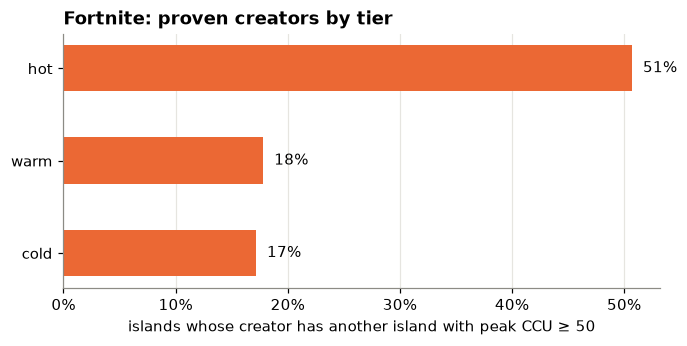

,tier,islands,creator_has_other_island_with_peak_50,creator_has_other_islands
0,hot,2708,0.507,0.862
1,warm,140670,0.178,0.887
2,cold,143542,0.172,0.878


In [8]:
track = q("""
select tier, count(*) as islands,
       avg((creator_best_peak_other >= 50)::int) as creator_has_other_island_with_peak_50,
       avg((creator_other_islands > 0)::int) as creator_has_other_islands
from fortnite_islands where is_listed group by 1
order by array_position(['hot', 'warm', 'cold'], tier)
""")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(track["tier"][::-1], track["creator_has_other_island_with_peak_50"][::-1], color=FORTNITE,
        height=0.5)
for i, v in enumerate(track["creator_has_other_island_with_peak_50"][::-1]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set(xlabel="islands whose creator has another island with peak CCU ≥ 50",
       title="Fortnite: proven creators by tier")
ax.grid(axis="y", visible=False)
plt.show()
track.round(3)

Islands with traction are far more likely to come from creators who already had a successful island.
Part of this is skill and part is audience: a known creator's new map gets favorites and
recommendations from day one. Any early-detection model has to control for it, otherwise "who made
it" will explain most of the signal. On Roblox, `creator_prev_hits` (previous games with 1M+ visits)
plays the same role.

## 7. Clones: title families

`title_clones` groups titles that reduce to the same words after cleaning (no emojis, bracket tags,
numbers or stopwords). It also links small variants such as "steal a brainrot **2**" to their
family. Families span both platforms.

In [9]:
q("""
select clone_key, any_value(clone_group_size) as titles,
       any_value(clone_group_size_roblox) as roblox,
       any_value(clone_group_size_fortnite) as fortnite
from title_clones where clone_key is not null
group by 1 order by titles desc limit 12
""")

,clone_key,titles,roblox,fortnite
0,1v1 build fight,6755,0.0,6755.0
1,box pvp,2099,0.0,2099.0
2,blue red vs,1997,0.0,1997.0
3,war zone,1550,0.0,1550.0
4,box fight,1469,0.0,1469.0
5,1v1 buildfight,1253,0.0,1253.0
6,1v1,1123,0.0,1123.0
7,party royale,690,0.0,690.0
8,escape room,609,13.0,596.0
9,all free,578,1.0,577.0


Fortnite's biggest families are generic PvP formats with thousands of copies each. Families that
exist **on both platforms** are formats that crossed over:

In [10]:
q("""
select clone_key, any_value(clone_group_size_roblox) as roblox,
       any_value(clone_group_size_fortnite) as fortnite
from title_clones where clone_key is not null
group by 1
having any_value(clone_group_size_roblox) >= 3 and any_value(clone_group_size_fortnite) >= 3
order by least(roblox, fortnite) desc limit 12
""")

,clone_key,roblox,fortnite
0,defense tower,50.0,24.0
1,egg steal,31.0,22.0
2,hide seek,16.0,243.0
3,escape room,13.0,596.0
4,city rp,10.0,80.0
5,formula racing,9.0,25.0
6,brainrot steal,9.0,78.0
7,prison run,22.0,7.0
8,garden grow,7.0,13.0
9,murder mystery,7.0,48.0


## 8. Fortnite retention

The Fortnite API reports D1 and D7 retention for each island and day. Median D1 retention is shown
by island size (peak CCU over the observed window).

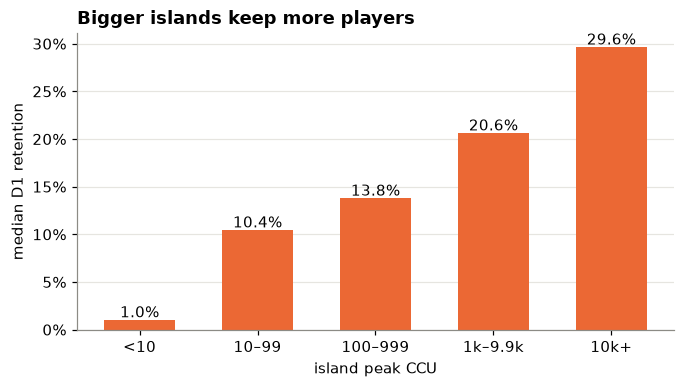

,size,islands,d1,d7
0,<10,17708,0.010,0.000
1,10–99,4055,0.104,0.023
2,100–999,978,0.138,0.045
3,1k–9.9k,102,0.206,0.076
4,10k+,13,0.296,0.162


In [11]:
ret = q("""
select case when peak_ccu < 10 then '<10'
            when peak_ccu < 100 then '10–99'
            when peak_ccu < 1000 then '100–999'
            when peak_ccu < 10000 then '1k–9.9k'
            else '10k+' end as size,
       min(peak_ccu) as lo, count(*) as islands,
       median(retention_d1_mean) as d1, median(retention_d7_mean) as d7
from fortnite_island_metrics where retention_d1_mean is not null
group by 1 order by lo
""")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(ret["size"], ret["d1"], color=FORTNITE, width=0.6)
for i, v in enumerate(ret["d1"]):
    ax.text(i, v + 0.003, f"{v:.1%}", ha="center")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
ax.set(xlabel="island peak CCU", ylabel="median D1 retention",
       title="Bigger islands keep more players")
ax.grid(axis="x", visible=False)
plt.show()
ret.drop(columns="lo").round(3)

Retention rises with island size. A small island's players almost never return the next day, while
large islands keep a meaningful share. Causality runs both ways (retained players also push the
island up in Discover), but D1 retention available after a single day is a strong candidate feature
for early detection.

## 9. Launch curves (Roblox)

The core of the project is new games observed from their first traction. `first_traction_at` is the
first snapshot with CCU ≥ 100. Games that already had traction when tracking started are marked
`traction_censored` and excluded here. The chart shows the hourly CCU of the biggest uncensored
launches, aligned on hours since first traction.

uncensored launches so far: 193


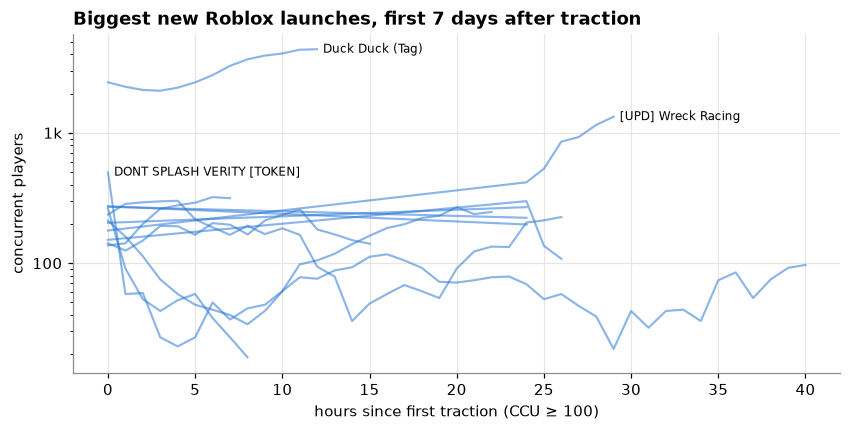

In [12]:
launches = q("""
with g as (
    select universe_id, name, first_traction_at from roblox_games
    where universe_id in (select universe_id from roblox_game_metrics where not traction_censored)
), s as (
    select g.universe_id, g.name,
           date_diff('minute', g.first_traction_at, s.snapshot_at) / 60.0 as hours,
           s.playing
    from roblox_snapshots s join g using (universe_id)
    where s.snapshot_at >= g.first_traction_at
      and s.snapshot_at < g.first_traction_at + interval 7 day
)
select * from s
where universe_id in (select universe_id from s group by 1 order by max(playing) desc limit 12)
order by universe_id, hours
""")
n_launch = q("select count(*) as n from roblox_game_metrics where not traction_censored").n[0]
print(f"uncensored launches so far: {n_launch}")

fig, ax = plt.subplots()
for _, d in launches.groupby("universe_id"):
    ax.plot(d["hours"], d["playing"], color=ROBLOX, alpha=0.55, linewidth=1.4)
top = launches.loc[launches.groupby("universe_id")["playing"].idxmax()].nlargest(3, "playing")
for _, r in top.iterrows():
    label = re.sub(r"[^\w\s\-:'!&().,\[\]]", "", r["name"]).strip()[:28]  # no emoji glyphs
    ax.annotate(label, (r["hours"], r["playing"]), xytext=(4, 0),
                textcoords="offset points", fontsize=8, va="center")
ax.set(yscale="log", xlabel="hours since first traction (CCU ≥ 100)", ylabel="concurrent players",
       title="Biggest new Roblox launches, first 7 days after traction")
ax.yaxis.set_major_formatter(fmt_k)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
plt.show()

Launches are already being caught, but none has been observed for more than a few days yet. This
section fills up week by week, and it is where the "explosion" and "sustained" definitions and the
early-detection model will come from. `roblox_game_metrics` / `fortnite_island_metrics` already
compute the curve features: `days_to_peak`, `slope_d1_7`, `half_life_days`, `sustained_ratio`.

## 10. Roblox charts

Which explore charts surface which games, and how big the games in each chart typically are.

In [13]:
q("""
select sort_name, count(distinct universe_id) as games, median(player_count)::int as median_ccu
from roblox_chart_positions group by 1 order by games desc limit 15
""")

,sort_name,games,median_ccu
0,Top Playing Now,154,20146
1,Up-and-Coming,147,5771
2,Top Trending,133,7247
3,Most Popular,123,13712
4,Trending in Simulation,116,7907
5,Top Revisited,115,1577
6,Top Earning,110,13699
7,Fun with Friends,108,5854
8,More When You Subscribe,106,698
9,Top Rated,105,588


"Up-and-Coming" and "Top Trending" hold smaller games than "Top Playing Now", which makes them the
early-detection charts. Entering one of them is itself a signal (`roblox_chart_positions` keeps the
rank every hour).

## Next steps

- **Define success** per platform: *explosion* (peak CCU ≥ X within 14 days of first traction) and
  *sustained* (CCU on days 30–60 ≥ 30% of the peak).
- **Early-detection model** from the first 3–7 days: growth slope, chart entries, D1 retention, title
  and clone features, creator track record. It needs ~6–8 weeks of observed launches.
- **Opportunity score** with week-over-week demand growth (Fortnite from the second week; Roblox
  next).

Questions and ideas are welcome in the dataset's discussion tab or on
[GitHub](https://github.com/Agustin-Molina/ugc-game-analytics).